# Exp 1 – Baseline Model | Random Forest

1. One-Hot Encoding (OHE) is used to convert categorical features into numerical format.
2. Class balancing is handled using class_weight='balanced' to give more importance to the minority churn class.
3. Stratified 5-Fold Cross-Validation generates Out-of-Fold (OOF) probabilities.
4. OOF probabilities are used to identify the best classification threshold based on F1 Score.
5. The final model is trained on the entire training dataset (100%).
6. The selected threshold is applied to train and test probabilities to generate 0 (Retained) and 1 (Churned) predictions.

## 0. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import make_column_transformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score
)
from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_predict,
    cross_validate,
    train_test_split
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder


In [2]:
df = pd.read_csv("../../task3/feature_eng_df.csv")

## 1. Separate Features and Target

In [3]:
date_cols = [
    'date_activ',
    'date_end',
    'date_modif_prod',
    'date_renewal'
]

X = df.drop(columns=['id', 'churn'] + date_cols)
y = df['churn']

print("Total missing values:", X.isna().sum().sum())

print("\nTarget distribution:")
print(y.value_counts())

print("\nTarget percentage:")
print((y.value_counts(normalize=True) * 100).round(2))

Total missing values: 33864

Target distribution:
churn
0    13187
1     1419
Name: count, dtype: int64

Target percentage:
churn
0    90.28
1     9.72
Name: proportion, dtype: float64


## 2. Train-Test Split

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nX_train:", X_train.shape)
print("X_test:", X_test.shape)


X_train: (11684, 104)
X_test: (2922, 104)


## 3. Identify Categorical and Numerical Columns

In [5]:
categorical_cols = X.select_dtypes(
    include=['object', 'category', 'bool']
).columns.tolist()

numerical_cols = X.select_dtypes(
    include=np.number
).columns.tolist()

print("\nCategorical columns:", categorical_cols)
print("Numerical columns:", len(numerical_cols))


Categorical columns: ['channel_sales', 'has_gas', 'origin_up']
Numerical columns: 101


## 4. Preprocessing Pipeline

In [6]:
categorical_pipeline = OneHotEncoder(
    handle_unknown='ignore'
)

preprocessor = make_column_transformer(
    (categorical_pipeline, categorical_cols),
    remainder='passthrough',
    verbose_feature_names_out=False,
    n_jobs=-1
)

## 5. Baseline Random Forest Pipeline

In [7]:
baseline_pipeline = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("model", RandomForestClassifier(
        class_weight='balanced',
        n_estimators=200,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        max_features='sqrt',
        random_state=42,
        n_jobs=-1
    ))
])

## 6. Stratified Cross Validation

In [8]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

## 7. Generate Out-of-Fold Probabilities

In [9]:
# Train 5 models using Stratified 5-Fold CV to generate OOF probabilities,
# which are used to find the best classification threshold.

y_prob_oof = cross_val_predict(
    baseline_pipeline,
    X_train,
    y_train,
    cv=cv,
    method='predict_proba',
    n_jobs=1
)[:, 1]

## 8. Precision-Recall Curve

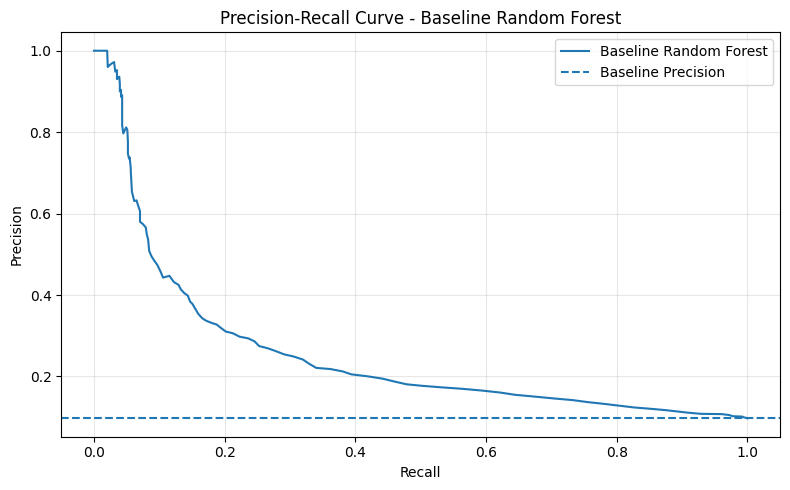

In [10]:
precision, recall, pr_thresholds = precision_recall_curve(
    y_train,
    y_prob_oof
)

plt.figure(figsize=(8, 5))

plt.plot(
    recall,
    precision,
    label='Baseline Random Forest'
)

plt.axhline(
    y=y_train.mean(),
    linestyle='--',
    label='Baseline Precision'
)

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve - Baseline Random Forest')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 9. Fine-Grained Threshold Analysis

In [11]:
# For each threshold, we generate a new set of 0 and 1 predictions using the same OOF probabilities.

threshold_values = np.arange(0.10, 0.251, 0.01)
fine_results = []

for threshold in threshold_values:
    y_pred = (y_prob_oof >= threshold).astype(int)

    fine_results.append({
        'Threshold': threshold,
        'Precision': precision_score(
            y_train, y_pred, zero_division=0
        ),
        'Recall': recall_score(
            y_train, y_pred, zero_division=0
        ),
        'F1 Score': f1_score(
            y_train, y_pred, zero_division=0
        )
    })

fine_threshold_df = pd.DataFrame(fine_results)

print("\n==== FINE-GRAINED THRESHOLD ANALYSIS ====")
print(fine_threshold_df.round(4).to_string(index=False))


==== FINE-GRAINED THRESHOLD ANALYSIS ====
 Threshold  Precision  Recall  F1 Score
      0.10     0.1604  0.6220    0.2551
      0.11     0.1698  0.5630    0.2609
      0.12     0.1770  0.5022    0.2618
      0.13     0.1878  0.4590    0.2666
      0.14     0.2004  0.4185    0.2710
      0.15     0.2124  0.3806    0.2726
      0.16     0.2211  0.3401    0.2680
      0.17     0.2415  0.3198    0.2752
      0.18     0.2544  0.2907    0.2714
      0.19     0.2692  0.2661    0.2676
      0.20     0.2862  0.2458    0.2645
      0.21     0.2976  0.2229    0.2549
      0.22     0.3103  0.2018    0.2445
      0.23     0.3277  0.1877    0.2387
      0.24     0.3368  0.1718    0.2275
      0.25     0.3542  0.1595    0.2199


## 10. Threshold Performance Visualization

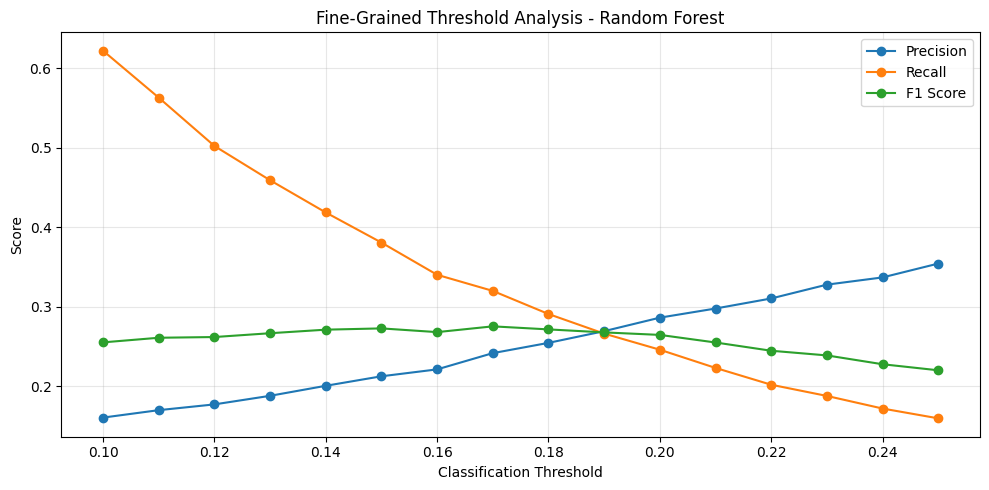

In [12]:
plt.figure(figsize=(10, 5))

plt.plot(
    fine_threshold_df['Threshold'],
    fine_threshold_df['Precision'],
    marker='o',
    label='Precision'
)

plt.plot(
    fine_threshold_df['Threshold'],
    fine_threshold_df['Recall'],
    marker='o',
    label='Recall'
)

plt.plot(
    fine_threshold_df['Threshold'],
    fine_threshold_df['F1 Score'],
    marker='o',
    label='F1 Score'
)

plt.xlabel('Classification Threshold')
plt.ylabel('Score')
plt.title('Fine-Grained Threshold Analysis - Random Forest')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 11. Select Best Threshold

In [13]:
best_threshold = fine_threshold_df.loc[
    fine_threshold_df['F1 Score'].idxmax(),
    'Threshold'
]

print("\n==== BEST THRESHOLD ====")
print("Best Threshold:", best_threshold)

print(
    fine_threshold_df.loc[
        fine_threshold_df['F1 Score'].idxmax()
    ]
)


==== BEST THRESHOLD ====
Best Threshold: 0.16999999999999998
Threshold    0.170000
Precision    0.241517
Recall       0.319824
F1 Score     0.275208
Name: 7, dtype: float64


## 12. Train Final Baseline Model

In [14]:
# Train the final model on the entire training dataset (100%),
# which will later use the best_threshold to generate 0/1 predictions.
baseline_pipeline.fit(X_train, y_train)

,steps,"[('preprocessing', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('onehotencoder', ...)]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,-1
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,False


## 13. Train Predictions

In [15]:
y_prob_train = baseline_pipeline.predict_proba(
    X_train
)[:, 1]

y_pred_train = (
    y_prob_train >= best_threshold
).astype(int) #means it return: If probability ≥ threshold → Prediction = 1 (Churned) and If probability < threshold → Prediction = 0 (Retained).

print('y_prob_train: ', y_prob_train.shape)
print('y_pred_train: ', y_pred_train.shape)

## 14. Test Predictions

In [16]:
y_prob_test = baseline_pipeline.predict_proba(
    X_test
)[:, 1]

y_pred_test = (
    y_prob_test >= best_threshold
).astype(int)


print('y_prob_test: ', y_prob_test.shape)
print('y_pred_test: ', y_pred_test.shape)

## 15. Define Metric Function

In [17]:
def calc_metrics(y_true, y_pred, y_prob):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(
            y_true, y_pred, zero_division=0
        ),
        'Recall': recall_score(
            y_true, y_pred, zero_division=0
        ),
        'F1 Score': f1_score(
            y_true, y_pred, zero_division=0
        ),
        'ROC-AUC': roc_auc_score(y_true, y_prob),
        'PR-AUC': average_precision_score(y_true, y_prob)
    }

## 16. Calculate Train and Test Metrics

In [18]:
train_metrics = calc_metrics(
    y_train, y_pred_train, y_prob_train
)

test_metrics = calc_metrics(
    y_test, y_pred_test, y_prob_test
)

print("\n==== TRAIN METRICS ====")
for metric, value in train_metrics.items():
    print(f"{metric:12}: {value:.4f}")

print("\n==== TEST METRICS ====")
for metric, value in test_metrics.items():
    print(f"{metric:12}: {value:.4f}")


==== TRAIN METRICS ====
Accuracy    : 0.9987
Precision   : 0.9870
Recall      : 1.0000
F1 Score    : 0.9934
ROC-AUC     : 1.0000
PR-AUC      : 1.0000

==== TEST METRICS ====
Accuracy    : 0.8402
Precision   : 0.2672
Recall      : 0.3697
F1 Score    : 0.3102
ROC-AUC     : 0.7076
PR-AUC      : 0.3277


## 17. Confusion Matrix

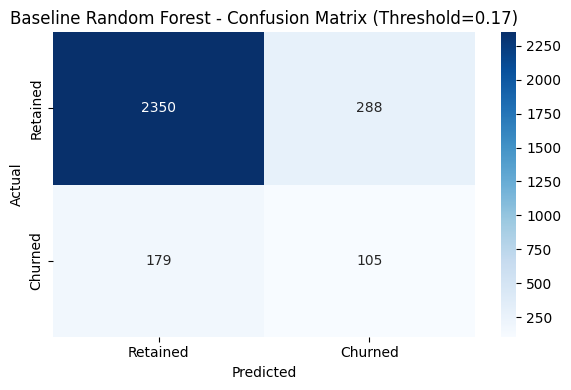

In [19]:
cm = confusion_matrix(y_test, y_pred_test)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Retained', 'Churned'],
    yticklabels=['Retained', 'Churned']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.title(
    f'Baseline Random Forest - Confusion Matrix '
    f'(Threshold={best_threshold:.2f})'
)

plt.tight_layout()
plt.show()

## 18. Classification Report

In [20]:
print("\n==== CLASSIFICATION REPORT ====")

print(classification_report(
    y_test,
    y_pred_test,
    target_names=['Retained', 'Churned'],
    zero_division=0
))


==== CLASSIFICATION REPORT ====
              precision    recall  f1-score   support

    Retained       0.93      0.89      0.91      2638
     Churned       0.27      0.37      0.31       284

    accuracy                           0.84      2922
   macro avg       0.60      0.63      0.61      2922
weighted avg       0.86      0.84      0.85      2922



## 19. Cross Validation Performance

In [21]:
scoring = {
    'Accuracy': 'accuracy',
    'Precision': 'precision',
    'Recall': 'recall',
    'F1': 'f1',
    'ROC_AUC': 'roc_auc',
    'PR_AUC': 'average_precision'
}

cv_results = cross_validate(
    baseline_pipeline,
    X_train,
    y_train,
    scoring=scoring,
    cv=cv,
    return_train_score=True,
    n_jobs=1
)

print("\n==== CROSS VALIDATION TRAIN SCORES ====")

for key, value in cv_results.items():
    if key.startswith('train'):
        print(
            f"{key} - Mean: {np.mean(value):.4f}, "
            f"Std: {np.std(value):.4f}"
        )

print("\n==== CROSS VALIDATION VALIDATION SCORES ====")

for key, value in cv_results.items():
    if key.startswith('test'):
        print(
            f"{key} - Mean: {np.mean(value):.4f}, "
            f"Std: {np.std(value):.4f}"
        )


==== CROSS VALIDATION TRAIN SCORES ====
train_Accuracy - Mean: 1.0000, Std: 0.0000
train_Precision - Mean: 1.0000, Std: 0.0000
train_Recall - Mean: 1.0000, Std: 0.0000
train_F1 - Mean: 1.0000, Std: 0.0000
train_ROC_AUC - Mean: 1.0000, Std: 0.0000
train_PR_AUC - Mean: 1.0000, Std: 0.0000

==== CROSS VALIDATION VALIDATION SCORES ====
test_Accuracy - Mean: 0.9065, Std: 0.0006
test_Precision - Mean: 0.9286, Std: 0.0904
test_Recall - Mean: 0.0414, Std: 0.0095
test_F1 - Mean: 0.0790, Std: 0.0172
test_ROC_AUC - Mean: 0.6859, Std: 0.0155
test_PR_AUC - Mean: 0.2543, Std: 0.0143


## 20. Feature Importance

In [22]:
rf_model = baseline_pipeline.named_steps['model']

feature_names = (
    baseline_pipeline
    .named_steps['preprocessing']
    .get_feature_names_out()
)

importances = rf_model.feature_importances_

feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(
    by='Importance',
    ascending=False
).reset_index(drop=True)

print("\n==== TOP 20 IMPORTANT FEATURES ====")

print(
    feature_importance_df.head(20).to_string(index=False)
)


==== TOP 20 IMPORTANT FEATURES ====
                   Feature  Importance
        margin_net_pow_ele    0.043028
   forecast_meter_rent_12m    0.026939
    margin_per_consumption    0.026029
      cons_last_month_diff    0.025212
     consumption_per_power    0.023626
       forecast_cons_ratio    0.023602
                  cons_12m    0.021819
        forecast_cons_diff    0.021508
price_consumption_exposure    0.021436
          margin_per_power    0.020408
   price_power_interaction    0.020075
        margin_per_product    0.019400
      customer_value_proxy    0.019373
         forecast_cons_12m    0.019288
                net_margin    0.019219
              months_activ    0.019111
 tenure_margin_interaction    0.018632
         months_modif_prod    0.017058
     cons_last_month_ratio    0.016520
                   pow_max    0.016395


# **Observations – Exp1:Baseline Random Forest Model**

**1. Dataset Overview**

- No missing values are present in the dataset.
- Target variable is highly imbalanced:
  - Retained (0): 13,187 (90.28%)
  - Churned (1): 1,419 (9.72%)
- Training data: 11,684 rows and 85 features.
- Testing data: 2,922 rows and 85 features.
- 3 categorical features and 82 numerical features.

**2. Precision-Recall Curve**

- The PR curve stays above the baseline precision (9.72%), indicating better performance than the baseline.
- Precision decreases as recall increases.
- The model identifies some churners with high precision but struggles to maintain precision when identifying more churners.
- Test PR-AUC is 0.3109, indicating scope for improvement.

**3. Threshold Optimization**

- Tested thresholds between 0.10 and 0.25.
- Lower thresholds increase recall but reduce precision.
- Higher thresholds increase precision but reduce recall.
- Best F1-score is **0.2790 at threshold 0.17**.
- Selected threshold: 0.17 instead of the default 0.50 to identify more potential churners.

**4. Confusion Matrix (Threshold = 0.17)**

- Correctly identified 106 churned customers (True Positives).
- Missed 178 actual churned customers (False Negatives).
- Incorrectly classified 320 retained customers as churners (False Positives).
- Correctly identified 2,318 retained customers (True Negatives).
- The model still misses a significant number of actual churners.

**5. Train vs Test Performance**

- Training accuracy is 99.89%, while testing accuracy is 82.96%.
- Training F1-score is 0.9943, while testing F1-score is 0.2986.
- Training ROC-AUC is 1.00, while testing ROC-AUC is 0.6940.
- Large differences between training and testing performance indicate **severe overfitting**.
- The model performs much better on training data than unseen data.

**6. Cross-Validation Results**

- Training scores are almost perfect across all folds.
- Validation accuracy is 90.62%, but validation recall is only 3.96%.
- Validation F1-score is 0.0758.
- The model struggles to identify minority-class churners during cross-validation.
- This indicates poor generalization and possible overfitting.

**7. Top 20 Feature Importance**

- `margin_net_pow_ele` is the most important feature (5.02%).
- `forecast_meter_rent_12m` is the second most important feature (3.39%).
- Consumption-related features such as `cons_last_month_diff`, `forecast_cons_diff` and `cons_12m` also contribute significantly.
- Pricing and customer activity features also play an important role in predictions.

**Overall Conclusion**

- Baseline Random Forest shows signs of severe overfitting.
- Despite achieving high training performance, its ability to identify churners on unseen data is limited.
- Threshold optimization improves churn detection compared with using the default 0.50 threshold.
- Further improvements are required to achieve better generalization and minority-class prediction.

Note: CV metrics were calculated at the default 0.50 threshold while test metrics use 0.17.Compare CV and test metrics cautiously.